<a href="https://colab.research.google.com/github/EhsanGhasemi423/INFS-8368/blob/main/28_Biderectional_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Bidirectional Recurrent Neural Networks

### Why Do We Need a Bidirectional RNN?

So far, our RNN language models have processed a sequence in one direction:

$$
X_1 \rightarrow X_2 \rightarrow X_3 \rightarrow \cdots \rightarrow X_T
$$

Therefore, when processing a token at time $t$, the hidden state contains
information about the **previous tokens**, but not the future tokens.

This is appropriate for tasks such as **next-token prediction**, because
future tokens are not available when making the prediction.

However, some sequence tasks can benefit from knowing the context on
**both sides** of the current token.

For example, consider predicting a missing word:

- I am ___.
- I am ___ hungry.
- I am ___ hungry, and I can eat half a pig.

The words appearing **after the blank** provide useful information for
determining the missing word.

### The Idea of a Bidirectional RNN

A bidirectional RNN uses **two RNNs** on the same sequence.

**Forward RNN:**

$$
X_1 \rightarrow X_2 \rightarrow X_3 \rightarrow \cdots \rightarrow X_T
$$

**Backward RNN:**

$$
X_T \rightarrow X_{T-1} \rightarrow X_{T-2} \rightarrow \cdots \rightarrow X_1
$$

At each position $t$, we therefore obtain two hidden states:

$$
\overrightarrow{H_t}
\qquad \text{and} \qquad
\overleftarrow{H_t}
$$

where:

- $\overrightarrow{H_t}$ contains information from the **left context**
- $\overleftarrow{H_t}$ contains information from the **right context**

The two representations are then concatenated:

$$
H_t =
[
\overrightarrow{H_t};
\overleftarrow{H_t}
]
$$

So the representation at position $t$ can use information from
**both directions**.





### Key Idea

**Standard RNN**

Past → Current

**Bidirectional RNN**

Past → **Current** ← Future

This makes bidirectional RNNs useful when the **entire input sequence is
available before making the prediction**.

> Bidirectional RNNs are generally not appropriate for ordinary
> next-token generation because future tokens are not yet available.

In [ ]:
# Bidirectional GRU using Keras

bidirectional_gru = tf.keras.Sequential([

    # Run a GRU both forward and backward through the sequence
    tf.keras.layers.Bidirectional(
        tf.keras.layers.GRU(
            32,
            return_sequences=True
        )
    )

])

In [ ]:
# Bidirectional simple RNN
tf.keras.layers.Bidirectional(
    tf.keras.layers.SimpleRNN(32, return_sequences=True)
)

# Bidirectional LSTM
tf.keras.layers.Bidirectional(
    tf.keras.layers.LSTM(32, return_sequences=True)
)

# Bidirectional GRU
tf.keras.layers.Bidirectional(
    tf.keras.layers.GRU(32, return_sequences=True)
)

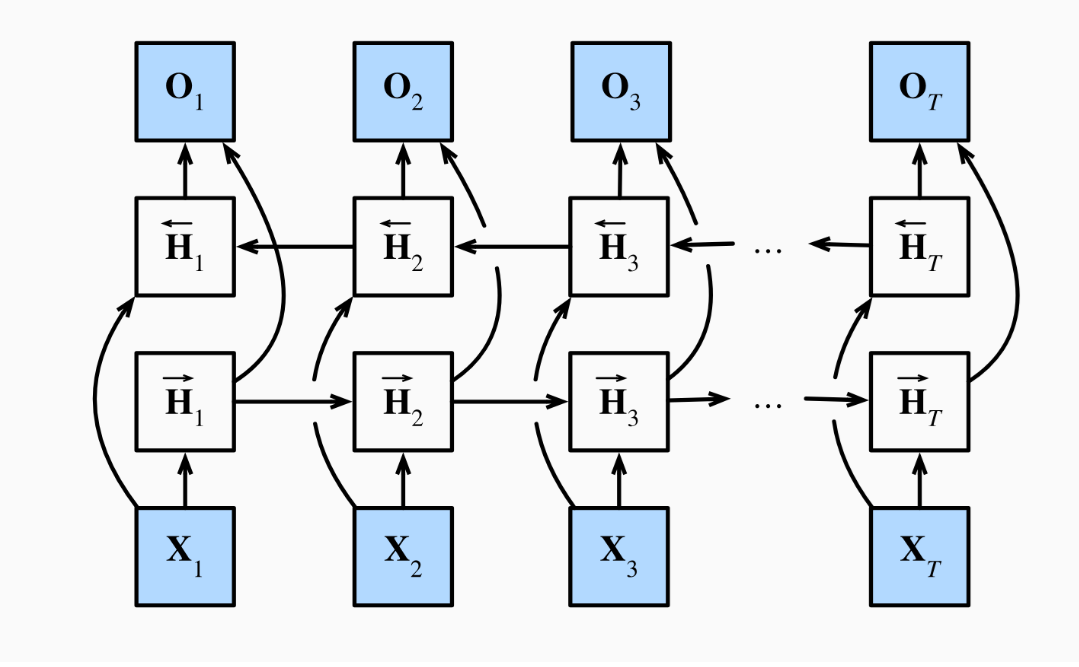

### What Does Keras Do Here?

`GRU(32)` creates the recurrent layer we already know.

`Bidirectional(...)` runs that GRU:

- once **forward** through the sequence
- once **backward** through the sequence

Keras then combines the representations from the two directions.


The important new idea is therefore **not a new GRU gate or memory
mechanism**.

It is simply:

> **Process the same sequence in both directions so that each position
> can use both left and right context.**

### How Are the Two Hidden States Computed?

At each position $t$, the bidirectional RNN calculates **two hidden states**.

#### 1. Forward Hidden State

The forward RNN uses the current input $X_t$ and the hidden state from
the **previous position**:

$$
\overrightarrow{H}_t
=
\phi
\left(
X_t W_{xh}^{(f)}
+
\overrightarrow{H}_{t-1} W_{hh}^{(f)}
+
b_h^{(f)}
\right)
$$

So:

$$
\overrightarrow{H}_{t-1}
\rightarrow
\overrightarrow{H}_t
$$

This representation contains information from the **left (past) context**.


#### 2. Backward Hidden State

The backward RNN processes the sequence in the opposite direction.

It uses the current input $X_t$ and the hidden state coming from the
**next position**:

$$
\overleftarrow{H}_t
=
\phi
\left(
X_t W_{xh}^{(b)}
+
\overleftarrow{H}_{t+1} W_{hh}^{(b)}
+
b_h^{(b)}
\right)
$$

So:

$$
\overleftarrow{H}_t
\leftarrow
\overleftarrow{H}_{t+1}
$$

This representation contains information from the **right (future) context**.






### Combining Both Directions

At position $t$, we now have:

$$
\overrightarrow{H}_t
\qquad \text{and} \qquad
\overleftarrow{H}_t
$$

They are **concatenated**, not added:

$$
H_t =
[
\overrightarrow{H}_t ;
\overleftarrow{H}_t
]
$$

Therefore:

$$
H_t
=
[\text{left-context representation};
\text{right-context representation}]
$$

If each direction has $h$ hidden units, the combined representation has
$2h$ values.

The output can then be calculated from this combined hidden state:

$$
O_t = H_t W_{hq} + b_q
$$

### Key Idea

At every position:

$$
\boxed{
\text{Past}
\rightarrow
\overrightarrow{H}_t
\quad+\quad
\overleftarrow{H}_t
\leftarrow
\text{Future}
}
$$

The model therefore represents the current position using information
from **both sides of the sequence**.